# ECE 3715 Mini-Project 2

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, special
from scipy.special import gamma
from scipy.stats import norm
import mp2lib

import time
project_start_time = time.time()

In [2]:
SEED = 1231083982
rng = np.random.default_rng(SEED)

step_rngs = rng.spawn(8)
bonus_b_rng = rng.spawn(1)[0]

rng1 = step_rngs[0]
rng_step4 = rng.spawn(1)[0]
rng_step6 = rng.spawn(1)[0]

N=100000

uniform_samples = rng1.uniform(0, 1, N)
exponential_samples = rng1.exponential(1, N)
gaussian_samples = rng1.normal(0, 1, N)
rayleigh_samples = rng1.rayleigh(1, N)

print("Project setup successful!")

Project setup successful!


### Step 1: Theoretical CDFs and PDFs

**1. Uniform Distribution U(0,1)**

Support: $0 \leq x \leq 1$

PDF:

$$
f(x)=
\begin{cases}
1, & 0 \leq x \leq 1\\
0, & \text{otherwise}
\end{cases}
$$

CDF:

$$
F(x)=
\begin{cases}
0, & x<0\\
x, & 0\leq x\leq 1\\
1, & x>1
\end{cases}
$$

**2. Exponential Distribution (rate = 1)**

Support: $x \geq 0$

PDF:

$$
f(x)=e^{-x}, \quad x\geq 0
$$

CDF:

$$
F(x)=1-e^{-x}, \quad x\geq 0
$$

Both functions are 0 for $x<0$.

**3. Standard Gaussian Distribution N(0,1)**

Support: $-\infty < x < \infty$

PDF:

$$
f(x)=\frac{1}{\sqrt{2\pi}}e^{-x^2/2}
$$

CDF:

$$
F(x)=\frac{1}{\sqrt{2\pi}}
\int_{-\infty}^{x}e^{-t^2/2}\,dt
$$

**4. Rayleigh Distribution (scale = 1)**

Support: $x \geq 0$

PDF:

$$
f(x)=xe^{-x^2/2}, \quad x\geq 0
$$

CDF:

$$
F(x)=1-e^{-x^2/2}, \quad x\geq 0
$$

Both functions are 0 for $x<0$.

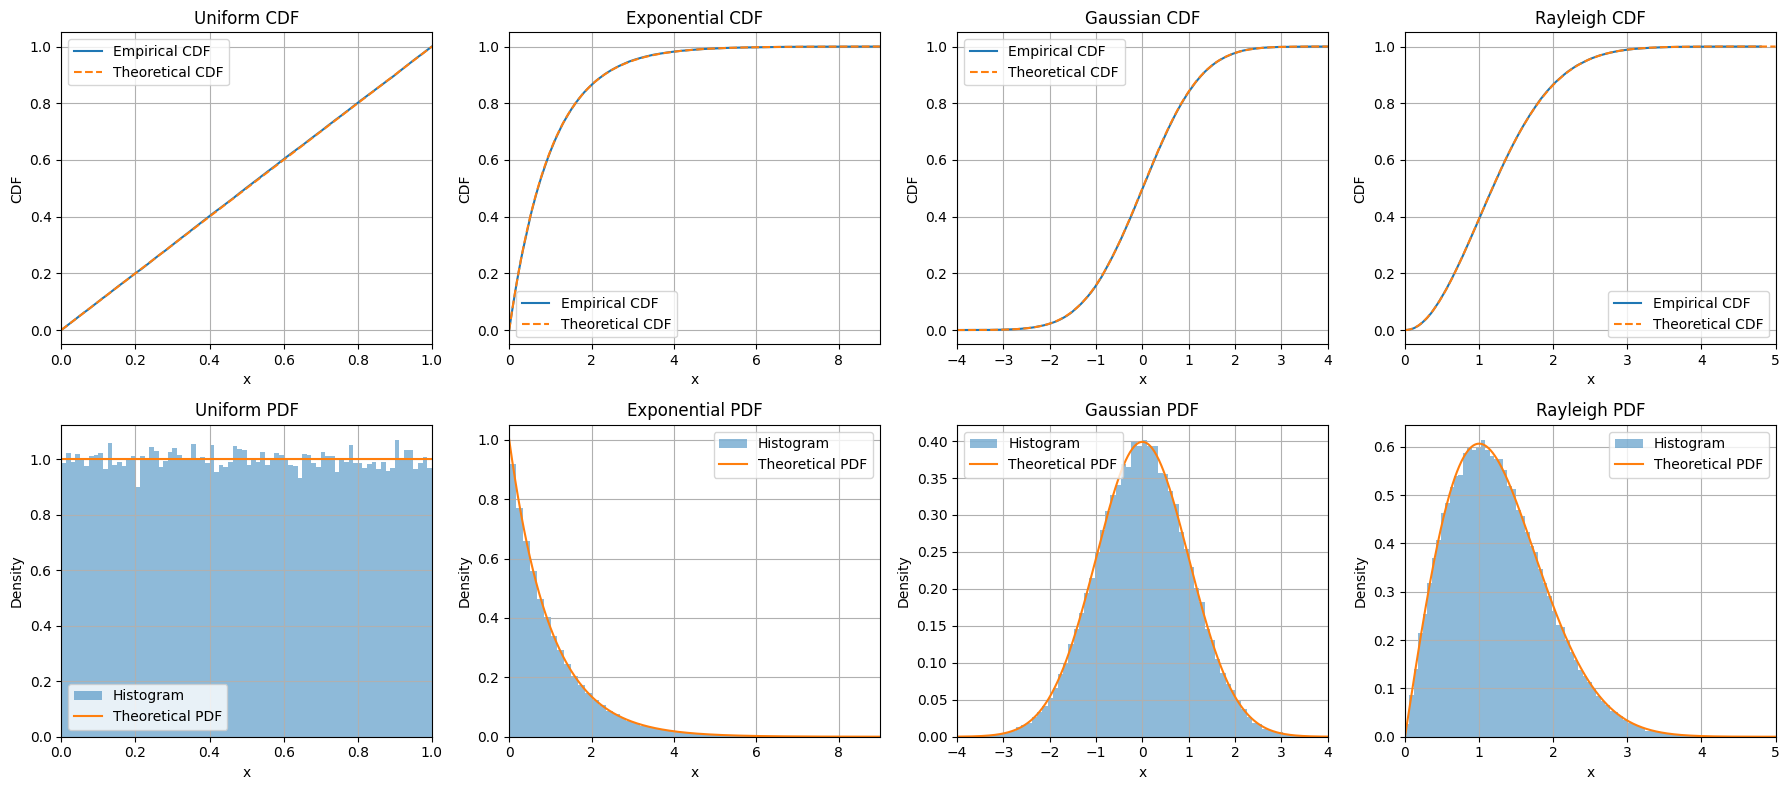

In [3]:
# Step 1: Figure 1 - CDFs and PDFs

distributions = [
    ("Uniform", uniform_samples, stats.uniform(), (0, 1)),
    ("Exponential", exponential_samples, stats.expon(), (0, 9)),
    ("Gaussian", gaussian_samples, stats.norm(), (-4, 4)),
    ("Rayleigh", rayleigh_samples, stats.rayleigh(), (0, 5))
]

fig, axes = plt.subplots(2, 4, figsize=(18, 8))

for i, (name, samples, dist, limits) in enumerate(distributions):

    x = np.linspace(limits[0], limits[1], 500)

    # Empirical CDF
    sorted_samples = np.sort(samples)
    empirical_cdf = np.arange(1, N + 1) / N

    axes[0, i].plot(sorted_samples, empirical_cdf,
                    label="Empirical CDF")
    axes[0, i].plot(x, dist.cdf(x), "--",
                    label="Theoretical CDF")

    axes[0, i].set_title(name + " CDF")
    axes[0, i].set_xlabel("x")
    axes[0, i].set_ylabel("CDF")
    axes[0, i].set_xlim(limits)
    axes[0, i].legend()
    axes[0, i].grid(True)

    # Histogram and theoretical PDF
    axes[1, i].hist(samples, bins=80, density=True,
                    alpha=0.5, label="Histogram")
    axes[1, i].plot(x, dist.pdf(x),
                    label="Theoretical PDF")

    axes[1, i].set_title(name + " PDF")
    axes[1, i].set_xlabel("x")
    axes[1, i].set_ylabel("Density")
    axes[1, i].set_xlim(limits)
    axes[1, i].legend()
    axes[1, i].grid(True)

plt.tight_layout()
plt.show()

### Figure 1 Interpretation

Figure 1 compares the empirical and theoretical CDFs
and PDFs for the four distributions using 100,000 samples
each. The empirical CDFs closely follow the theoretical
curves, and the normalized histograms show the expected
density shapes.

The uniform distribution has a constant density, the
exponential distribution decreases as x increases, the
Gaussian distribution is symmetric, and the Rayleigh
distribution increases to a peak before decreasing.

The KS statistics are 0.002775, 0.003457, 0.002861,
and 0.002199, respectively. All four values are below
the 95% critical value of 0.004301, so none of the
distributions is rejected by the KS test.

### Mean and Median Comparison

The exponential distribution is right-skewed, so its
long right tail pulls the mean above the median,
making the mean approximately 1.44 times the median.

The Gaussian distribution is symmetric around zero,
so its theoretical mean and median are both zero.

In [4]:
# Step 1: KS Statistics

from mp2lib import ks_statistic

critical_value = 1.36 / np.sqrt(N)

print("Step 1: KS Statistics")
print(f"95% Critical Value: {critical_value:.6f}")
print("-" * 50)
print(f"{'Distribution':<15} {'KS Statistic':<15} {'Result'}")

for name, samples, dist, limits in distributions:
    ks = ks_statistic(samples, dist.cdf)
    result = "Pass" if ks < critical_value else "Fail"
    print(f"{name:<15} {ks:<15.6f} {result}")

Step 1: KS Statistics
95% Critical Value: 0.004301
--------------------------------------------------
Distribution    KS Statistic    Result
Uniform         0.002775        Pass
Exponential     0.003457        Pass
Gaussian        0.002861        Pass
Rayleigh        0.002199        Pass


In [5]:
# Step 1: Mean, Median, and Variance

print("Exponential Distribution")
print(f"Sample Mean: {np.mean(exponential_samples):.4f}")
print(f"Theoretical Mean: {1.0:.4f}")
print(f"Sample Median: {np.median(exponential_samples):.4f}")
print(f"Theoretical Median: {np.log(2):.4f}")
print(f"Sample Variance: {np.var(exponential_samples, ddof=1):.4f}")
print(f"Theoretical Variance: {1.0:.4f}")

print("\nRayleigh Distribution")
print(f"Sample Mean: {np.mean(rayleigh_samples):.4f}")
print(f"Theoretical Mean: {np.sqrt(np.pi / 2):.4f}")
print(f"Sample Median: {np.median(rayleigh_samples):.4f}")
print(f"Theoretical Median: {np.sqrt(2 * np.log(2)):.4f}")
print(f"Sample Variance: {np.var(rayleigh_samples, ddof=1):.4f}")
print(f"Theoretical Variance: {(4 - np.pi) / 2:.4f}")

Exponential Distribution
Sample Mean: 1.0016
Theoretical Mean: 1.0000
Sample Median: 0.6978
Theoretical Median: 0.6931
Sample Variance: 0.9978
Theoretical Variance: 1.0000

Rayleigh Distribution
Sample Mean: 1.2533
Theoretical Mean: 1.2533
Sample Median: 1.1807
Theoretical Median: 1.1774
Sample Variance: 0.4285
Theoretical Variance: 0.4292


### Theoretical Mean, Median, and Variance

**Exponential Distribution (rate = 1)**

Mean: $\mu = \frac{1}{\lambda} = 1$

Median: $m = \frac{\ln 2}{\lambda} = 0.6931$

Variance: $\sigma^2 = \frac{1}{\lambda^2} = 1$

**Rayleigh Distribution (scale = 1)**

Mean: $\mu = \sigma\sqrt{\frac{\pi}{2}} = 1.2533$

Median: $m = \sigma\sqrt{2\ln 2} = 1.1774$

Variance: $\mathrm{Var}(X) = \frac{4-\pi}{2}\sigma^2 = 0.4292$

## Step 2: Build Your Own Generator by Inversion

### Inverse CDF Sampling

If $U$ is uniformly distributed on $[0,1]$ and $F$ is a continuous, strictly increasing CDF, we can generate a random variable $X$ with CDF $F$ using

$$
X=F^{-1}(U).
$$

Proof:

$$
P(X\leq x)=P(F^{-1}(U)\leq x)
$$

$$
=P(U\leq F(x))=F(x).
$$

Therefore, $F^{-1}(U)$ has the desired CDF.

### Exponential Inverse CDF

For an exponential distribution with rate $\lambda$,

$$
F(x)=1-e^{-\lambda x}.
$$

Setting $u=F(x)$,

$$
u=1-e^{-\lambda x}
$$

$$
1-u=e^{-\lambda x}
$$

$$
\ln(1-u)=-\lambda x.
$$

Solving for $x$ gives

$$
F^{-1}(u)=\frac{-\ln(1-u)}{\lambda}.
$$

### Rayleigh Inverse CDF

For a Rayleigh distribution with scale $\sigma$,

$$
F(x)=1-e^{-x^2/(2\sigma^2)}.
$$

Setting $u=F(x)$,

$$
1-u=e^{-x^2/(2\sigma^2)}
$$

$$
\ln(1-u)=-\frac{x^2}{2\sigma^2}
$$

$$
x^2=-2\sigma^2\ln(1-u).
$$

Therefore,

$$
F^{-1}(u)=\sigma\sqrt{-2\ln(1-u)}.
$$

In [6]:
# Step 2: Inverse CDF Sampling

from mp2lib import (
    inv_cdf_exponential,
    inv_cdf_rayleigh,
    sample_by_inversion,
    ks_statistic
)

N2 = 100000
rng2 = step_rngs[1]

# Generate samples using our inverse CDF functions
exp_inv = sample_by_inversion(
    inv_cdf_exponential, N2, rng2, lam=1
)

ray_inv = sample_by_inversion(
    inv_cdf_rayleigh, N2, rng2, sigma=1
)

# Generate samples using NumPy for comparison
exp_lib = rng2.exponential(1, N2)
ray_lib = rng2.rayleigh(1, N2)

# KS statistics against the theoretical CDF
ks_exp = ks_statistic(exp_inv, stats.expon.cdf)
ks_ray = ks_statistic(ray_inv, stats.rayleigh.cdf)

ks_exp_lib = ks_statistic(exp_lib, stats.expon.cdf)
ks_ray_lib = ks_statistic(ray_lib, stats.rayleigh.cdf)

critical2 = 1.36 / np.sqrt(N2)

print("Step 2: Inverse CDF Sampling")
print(f"95% Critical Value: {critical2:.6f}")

print("\nExponential Distribution")
print(f"Inversion KS: {ks_exp:.6f}")
print(f"Library KS: {ks_exp_lib:.6f}")
print("Inversion passes:", ks_exp < critical2)

print("\nRayleigh Distribution")
print(f"Inversion KS: {ks_ray:.6f}")
print(f"Library KS: {ks_ray_lib:.6f}")
print("Inversion passes:", ks_ray < critical2)

# Two-sample comparison against the library generators
print("\nTwo-Sample KS Comparison")
print(f"Exponential: {stats.ks_2samp(exp_inv, exp_lib).statistic:.6f}")
print(f"Rayleigh: {stats.ks_2samp(ray_inv, ray_lib).statistic:.6f}")

Step 2: Inverse CDF Sampling
95% Critical Value: 0.004301

Exponential Distribution
Inversion KS: 0.001600
Library KS: 0.003157
Inversion passes: True

Rayleigh Distribution
Inversion KS: 0.002912
Library KS: 0.004225
Inversion passes: True

Two-Sample KS Comparison
Exponential: 0.003090
Rayleigh: 0.004590


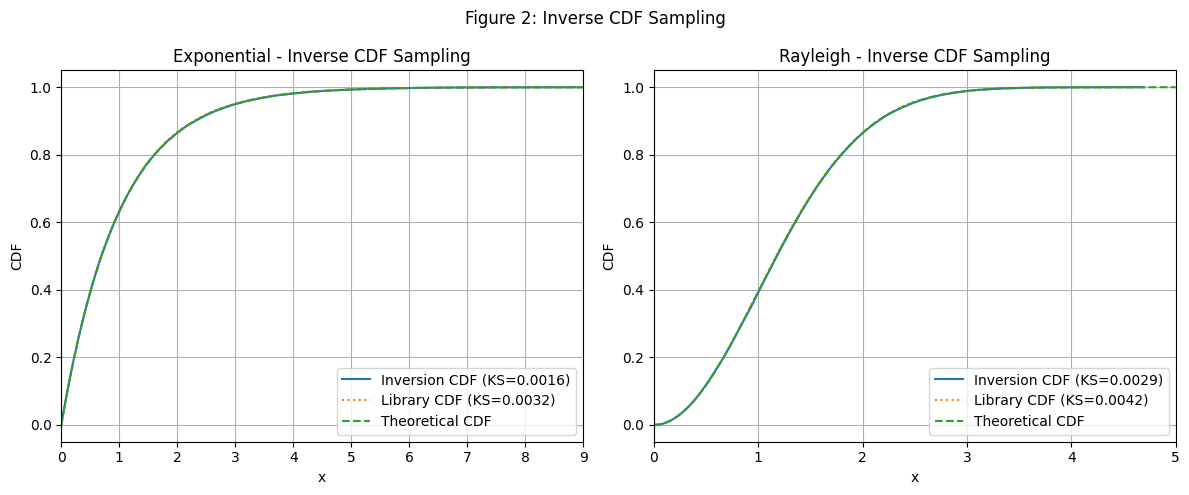

In [7]:
# Step 2: Figure 2

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

data2 = [
    ("Exponential", exp_inv, exp_lib,
     stats.expon, ks_exp, ks_exp_lib, (0, 9)),

    ("Rayleigh", ray_inv, ray_lib,
     stats.rayleigh, ks_ray, ks_ray_lib, (0, 5))
]

for ax, (name, inv_samples, lib_samples,
         dist, ks_inv, ks_lib, limits) in zip(axes, data2):

    x = np.linspace(limits[0], limits[1], 500)

    inv_sorted = np.sort(inv_samples)
    lib_sorted = np.sort(lib_samples)

    ecdf = np.arange(1, N2 + 1) / N2

    ax.plot(inv_sorted, ecdf,
            label=f"Inversion CDF (KS={ks_inv:.4f})")

    ax.plot(lib_sorted, ecdf, ":",
            label=f"Library CDF (KS={ks_lib:.4f})")

    ax.plot(x, dist.cdf(x), "--",
            label="Theoretical CDF")

    ax.set_title(name + " - Inverse CDF Sampling")
    ax.set_xlabel("x")
    ax.set_ylabel("CDF")
    ax.set_xlim(limits)
    ax.legend()
    ax.grid(True)

plt.suptitle("Figure 2: Inverse CDF Sampling")
plt.tight_layout()
plt.show()

### Figure 2 Interpretation

Figure 2 compares samples generated using inverse CDF
sampling with the theoretical CDFs and NumPy's library
generators.

Both inverse CDF generators closely follow their
theoretical distributions. The exponential inversion KS
statistic is approximately 0.0016, and the Rayleigh
inversion KS statistic is approximately 0.0029. Both are
below the 95% critical value of 0.0043.

The library-generated samples also agree with their
theoretical CDFs. These results support the correctness
of the inverse CDF sampling implementations.

### Edge Case Handling

The implementation uses `np.log1p(-u)` to calculate
$\ln(1-u)$ accurately, including when $u$ is close to zero.

When $u=0$, both inverse CDF functions return zero,
which is a valid value on their supports.

NumPy's `rng.random()` generates values in $[0,1)$,
so it does not produce $u=1$, which would cause
the inverse CDF to become infinite.

### Equivalent Exponential Inverse Forms

Both $-\ln(U)/\lambda$ and $-\ln(1-U)/\lambda$ generate
the same exponential distribution because $U$ and
$1-U$ are both uniformly distributed on $[0,1]$.

Our implementation uses $-\ln(1-U)/\lambda$.

## Step 3: A Function of a Random Variable

Let $X\sim N(0,1)$ and define $Y=X^2$.

### Derivation of the CDF

Since $Y=X^2$, the support of $Y$ is $y\geq 0$.

For $y>0$,

$$
F_Y(y)=P(Y\leq y)
$$

$$
=P(X^2\leq y)
$$

$$
=P(-\sqrt{y}\leq X\leq\sqrt{y}).
$$

Using the standard Gaussian CDF $\Phi$,

$$
F_Y(y)=\Phi(\sqrt{y})-\Phi(-\sqrt{y}).
$$

Because the standard Gaussian is symmetric,

$$
\Phi(-a)=1-\Phi(a).
$$

Therefore,

$$
F_Y(y)=2\Phi(\sqrt{y})-1,\qquad y>0.
$$

For $y\leq 0$, the CDF is zero.

### Derivation of the PDF

Differentiate the CDF:

$$
f_Y(y)=\frac{d}{dy}[2\Phi(\sqrt{y})-1].
$$

Using the chain rule,

$$
f_Y(y)=2\phi(\sqrt{y})\frac{1}{2\sqrt{y}},
$$

where

$$
\phi(x)=\frac{1}{\sqrt{2\pi}}e^{-x^2/2}.
$$

Thus,

$$
f_Y(y)=\frac{1}{\sqrt{2\pi y}}e^{-y/2},
\qquad y>0.
$$

The density is zero for $y<0$.

### Why the Density Diverges Near Zero

As $y$ approaches zero from the positive side,

$$
f_Y(y)\sim\frac{1}{\sqrt{2\pi}}y^{-1/2}.
$$

The density becomes unbounded because the squaring
transformation is flat near $x=0$. A small interval
around zero in the original Gaussian distribution is
compressed into an even smaller interval after squaring.

However, the total probability remains finite because
the singularity $y^{-1/2}$ is integrable near zero:

$$
\int_0^\epsilon y^{-1/2}\,dy=2\sqrt{\epsilon}.
$$

Therefore, an unbounded PDF can still integrate to one.

### Analytical Mean and Variance

Since $Y=X^2$ and $X$ is standard Gaussian,

$$
E[Y]=E[X^2]=1.
$$

Also,

$$
E[Y^2]=E[X^4]=3.
$$

Therefore,

$$
\operatorname{Var}(Y)=E[Y^2]-(E[Y])^2
$$

$$
=3-1^2=2.
$$

### Analytical Probabilities and Median

For any $a>0$,

$$
P(Y\leq a)=2\Phi(\sqrt{a})-1.
$$

Therefore,

$$
P(Y\leq 1)=2\Phi(1)-1\approx 0.6827,
$$

and

$$
P(Y\leq 0.1)=2\Phi(\sqrt{0.1})-1\approx 0.2482.
$$

For the median $m$, set $F_Y(m)=0.5$:

$$
2\Phi(\sqrt{m})-1=0.5
$$

$$
\Phi(\sqrt{m})=0.75
$$

$$
m=[\Phi^{-1}(0.75)]^2\approx 0.4549.
$$

In [8]:
# Step 3: Gaussian Transformation Y = X^2

from scipy.integrate import quad

N3 = 1000000
rng3 = step_rngs[2]

# Generate standard Gaussian samples
x3 = rng3.normal(0, 1, N3)

# Transform X into Y
y3 = x3**2

# Analytical PDF
def y_pdf(y):
    return np.exp(-y / 2) / np.sqrt(2 * np.pi * y)

# Verify the PDF integrates to 1
integral, integration_error = quad(y_pdf, 0, np.inf)

print("Step 3: Gaussian Transformation")
print(f"PDF integral: {integral:.6f}")
print(f"Integration error estimate: {integration_error:.2e}")

# Analytical and empirical probabilities
p1_theory = 2 * stats.norm.cdf(1) - 1
p01_theory = 2 * stats.norm.cdf(np.sqrt(0.1)) - 1

p1_sample = np.mean(y3 <= 1)
p01_sample = np.mean(y3 <= 0.1)

# Median
median_theory = stats.norm.ppf(0.75)**2
median_sample = np.median(y3)

# Mean and variance
mean_theory = 1.0
var_theory = 2.0

mean_sample = np.mean(y3)
var_sample = np.var(y3, ddof=1)

print("\nComparison of Analytical and Empirical Values")
print(f"{'Statistic':<20} {'Analytical':>12} {'Empirical':>12}")
print("-" * 48)

results3 = [
    ("P(Y <= 1)", p1_theory, p1_sample),
    ("P(Y <= 0.1)", p01_theory, p01_sample),
    ("Median", median_theory, median_sample),
    ("Mean", mean_theory, mean_sample),
    ("Variance", var_theory, var_sample)
]

for name, theoretical, empirical in results3:
    print(f"{name:<20} {theoretical:>12.4f} {empirical:>12.4f}")

Step 3: Gaussian Transformation
PDF integral: 1.000000
Integration error estimate: 1.96e-11

Comparison of Analytical and Empirical Values
Statistic              Analytical    Empirical
------------------------------------------------
P(Y <= 1)                  0.6827       0.6825
P(Y <= 0.1)                0.2482       0.2479
Median                     0.4549       0.4554
Mean                       1.0000       0.9986
Variance                   2.0000       1.9952


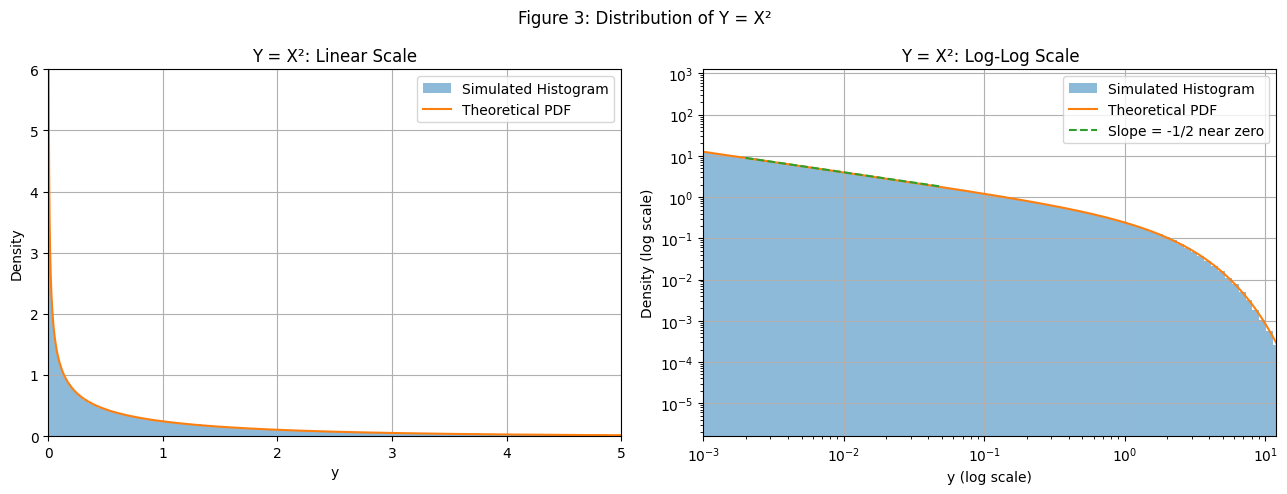

In [9]:
# Step 3: Figure 3

# Log-spaced bins to show the behavior near zero
bins3 = np.geomspace(1e-6, 20, 150)
x_plot3 = np.geomspace(1e-5, 20, 1000)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Panel 1: Linear axes
axes[0].hist(y3, bins=bins3, density=True,
             alpha=0.5, label="Simulated Histogram")

axes[0].plot(x_plot3, y_pdf(x_plot3),
             label="Theoretical PDF")

axes[0].set_title("Y = X²: Linear Scale")
axes[0].set_xlabel("y")
axes[0].set_ylabel("Density")
axes[0].set_xlim(0, 5)
axes[0].set_ylim(0, 6)
axes[0].legend()
axes[0].grid(True)

# Panel 2: Log-log axes
axes[1].hist(y3, bins=bins3, density=True,
             alpha=0.5, label="Simulated Histogram")

axes[1].plot(x_plot3, y_pdf(x_plot3),
             label="Theoretical PDF")

# Reference line showing slope -1/2 near zero
x_ref = np.geomspace(0.002, 0.05, 100)
y_ref = (1 / np.sqrt(2 * np.pi)) * x_ref**(-0.5)

axes[1].plot(x_ref, y_ref, "--",
             label="Slope = -1/2 near zero")

axes[1].set_xscale("log")
axes[1].set_yscale("log")

axes[1].set_title("Y = X²: Log-Log Scale")
axes[1].set_xlabel("y (log scale)")
axes[1].set_ylabel("Density (log scale)")
axes[1].set_xlim(1e-3, 12)
axes[1].legend()
axes[1].grid(True)

plt.suptitle("Figure 3: Distribution of Y = X²")
plt.tight_layout()
plt.show()

### Figure 3 Interpretation

Figure 3 compares the simulated distribution of
$Y=X^2$ with its theoretical PDF using one million
samples. Logarithmically spaced bins are used to
better capture the behavior near zero.

On the linear scale, the density rises sharply near
zero and decreases as $y$ increases. The log-log
plot makes the divergence more visible.

Near zero,

$$
f_Y(y)\approx\frac{1}{\sqrt{2\pi}}y^{-1/2}.
$$

Taking logarithms gives

$$
\ln f_Y(y)\approx
-\frac{1}{2}\ln y-\frac{1}{2}\ln(2\pi).
$$

Therefore, the log-log slope approaches $-1/2$.

The numerical integration confirms that the PDF
integrates to approximately one despite diverging
near zero.

The empirical probabilities, median, mean, and
variance are close to their analytical values.

The median is substantially smaller than the mean,
reflecting the concentration of probability near
zero and the long right tail of the distribution.


# Step 4:  Expectation and moments

First Four Raw Rayleigh Moments
 k  Sample Moment  Theoretical  Difference (SE)
 1       1.251077     1.253314        -1.082112
 2       1.992650     2.000000        -1.166407
 3       3.738944     3.759942        -1.145987
 4       7.941017     8.000000        -1.044646

Running Mean & Variance of Pareto Samples
      N  Sample Mean  Sample Variance
   1000     2.702950        27.681442
  10000     2.951645        63.521025
 100000     2.965161       180.453053
1000000     2.965161       180.453053


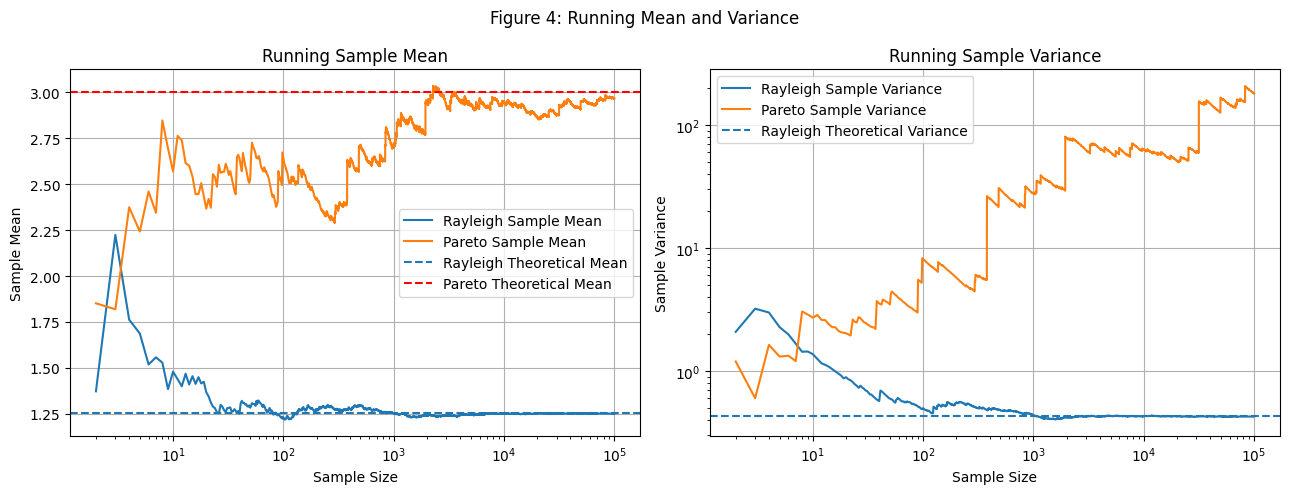

In [10]:
# 1. Rayleigh moments
rayleigh = rng_step4.rayleigh(scale=1, size=N)
results = []

for k in range(1, 5):
    sample_mmnt = np.mean(rayleigh**k)
    theoretical_mmnt = 2**(k/2) * gamma(1 + k/2)

    std_err = np.std(rayleigh**k, ddof=1) / np.sqrt(N)
    diff = (sample_mmnt - theoretical_mmnt) / std_err

    results.append([k, sample_mmnt, theoretical_mmnt, diff])

step4_table = pd.DataFrame(results,columns=["k", "Sample Moment", "Theoretical", "Difference (SE)"])

print("First Four Raw Rayleigh Moments")
print(step4_table.to_string(index=False))

# 3. Running mean and variance of Pareto samples
pareto = rng_step4.pareto(a=1.5, size=N)+1

sample_sizes = [1000, 10000, 100000, 1000000]
results = []

for i in sample_sizes:
    samples = pareto[:i]

    sample_mean = np.mean(samples)
    sample_var = np.var(samples, ddof=1)

    results.append([i, sample_mean, sample_var])

step4_pareto_table = pd.DataFrame(results, columns=["N", "Sample Mean", "Sample Variance"])

print("\nRunning Mean & Variance of Pareto Samples")
print(step4_pareto_table.to_string(index=False))


# Figure 4: Running mean & variance for Rayleigh and Pareto distributions
running_sample_sizes = np.arange(2, N + 1)

rayleigh_mean = np.cumsum(rayleigh)[1:] / running_sample_sizes
pareto_mean = np.cumsum(pareto)[1:] / running_sample_sizes

rayleigh_var = (np.cumsum(rayleigh**2)[1:] - running_sample_sizes * rayleigh_mean**2)/(running_sample_sizes - 1)
pareto_var = (np.cumsum(pareto**2)[1:] - running_sample_sizes * pareto_mean**2)/(running_sample_sizes - 1)

fig,axes = plt.subplots(1, 2, figsize=(13,5))

axes[0].plot(running_sample_sizes, rayleigh_mean, label="Rayleigh Sample Mean")
axes[0].plot(running_sample_sizes, pareto_mean, label="Pareto Sample Mean")

axes[0].axhline(np.sqrt(np.pi / 2), linestyle="--",label="Rayleigh Theoretical Mean")
axes[0].axhline(3, color="red", linestyle="--",label="Pareto Theoretical Mean")
axes[0].set_xscale("log")
axes[0].set_title("Running Sample Mean")
axes[0].set_xlabel("Sample Size")
axes[0].set_ylabel("Sample Mean")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(running_sample_sizes, rayleigh_var, label="Rayleigh Sample Variance")
axes[1].plot(running_sample_sizes, pareto_var, label="Pareto Sample Variance")

axes[1].axhline((4-np.pi)/2, linestyle="--",label="Rayleigh Theoretical Variance")

axes[1].set_xscale("log")
axes[1].set_yscale("log")
axes[1].set_title("Running Sample Variance")
axes[1].set_xlabel("Sample Size")
axes[1].set_ylabel("Sample Variance")
axes[1].legend()
axes[1].grid(True)

plt.suptitle("Figure 4: Running Mean and Variance")
plt.tight_layout()
plt.show()


**Analysis of Pareto Distribution**

Given the density

$$
f(x) = 1.5x^{-2.5}, \quad x \geq 1
$$

and the expected value for continuous random variables

$$
\mu = E[X] = \int_{-\infty}^{\infty} xf(x)\,dx
$$

With the Pareto distribution,

$$
E[X] = \int_1^\infty 1.5x^{-1.5}\,dx
$$

$$
= 1.5\int_1^\infty x^{-1.5}\,dx
$$

$$
= \frac{1.5}{-0.5}[x^{-0.5}]_1^\infty
$$

$$
= -3(0-1)
$$

$$
= 3
$$

Because the expected value integrates to a finite value of 3, the mean for the Pareto distribution exists at 3.

The second moment is determined by:

$$
E[X^2] = \int_1^\infty x^2(1.5x^{-1.5})\,dx
$$

$$
= 1.5\int_1^\infty x^{-0.5}\,dx
$$

$$
= \frac{1.5}{0.5}[\sqrt{x}]_1^\infty
$$

$$
= 3(\infty-1)
$$

$$
= ∞
$$

The second moment does not exist as its integral does not result in a finite number.


**Explanation of Observations**

As the sample size increases, the sample mean is expected to settle near 3. The simulation above reflects this behavior of reaching the theoretical mean as the sample mean approximates 2.986 with increasing sample size. We observe large jumps in the sample variance as it fluctuates from 346.015 to 97.370 before increasing significantly to 442.432. Our code still prints the sample variance because its calculations are performed using a finite number of samples. The code can still calculate a finite sample variance because it uses a finite number of observations. The sample variance only shows how far the data varies from the sample mean.

**Practical Rule**

The practical rule for reporting error bars is to ensure that the variance of the measured data is finite. Infinite variance impacts the reliability of the error bars as outlier sample values can affect the sample variance.

# Step 5: The central limit theorem, and where it fails

Uniform Sums, Mean, Variance, & KS Statistics
 N  Mean  Variance  KS Statistic
 1   0.5  0.083333      0.056910
 2   1.0  0.166667      0.016968
 3   1.5  0.250000      0.010578
 5   2.5  0.416667      0.007027
10   5.0  0.833333      0.002783
30  15.0  2.500000      0.001652

Pareto Sums & KS Statistics
   N  KS Statistic
   1      0.442238
  10      0.396529
 100      0.382480
1000      0.355781


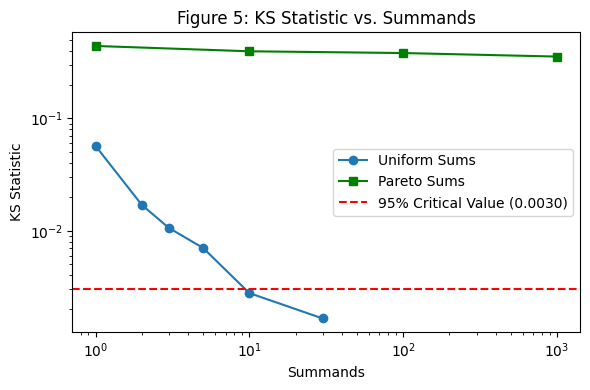

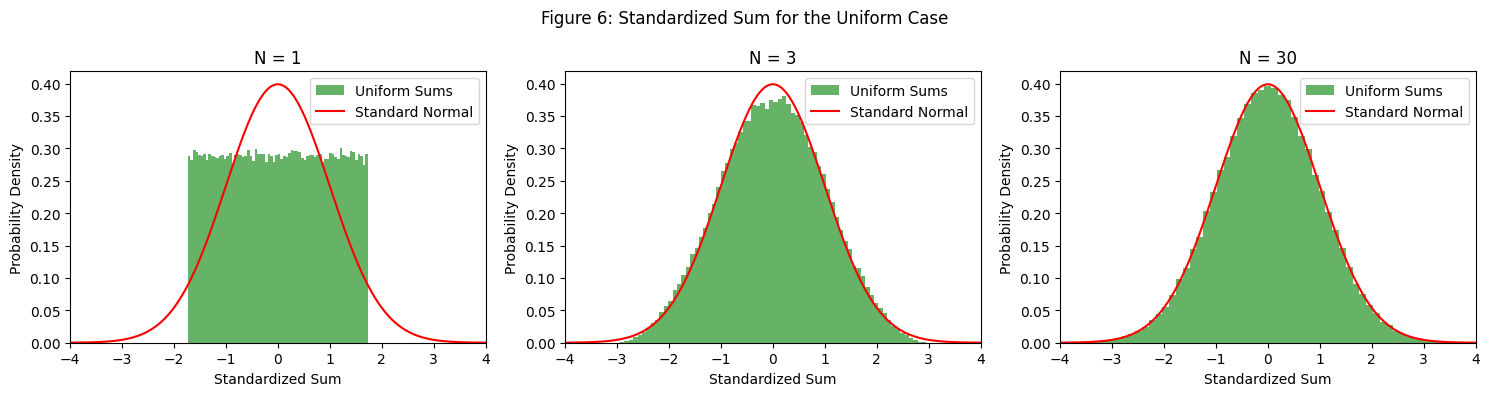

In [11]:
from scipy.stats import norm

rng_step5 = rng.spawn(1)[0]

num_samples = 2*(10**5)

# 1.
uniform_n = [1,2,3,5,10,30]
uniform_data = []
uniform_histogram = {}

for i in uniform_n:
    samples = rng_step5.uniform(0, 1, size=(num_samples, i))
    sums = np.sum(samples, axis=1)

    theoretical_mean = i/2
    theoretical_variance = i/12
    theoretical_stddev = np.sqrt(theoretical_variance)

    standardized_sums = (sums-theoretical_mean) / theoretical_stddev

    ks_val = ks_statistic(standardized_sums, norm.cdf)

    uniform_data.append([i, theoretical_mean, theoretical_variance, ks_val])

    if i==1 or i==3 or i==30:
        uniform_histogram[i] = standardized_sums

uniform_results = pd.DataFrame(uniform_data, columns=["N", "Mean", "Variance", "KS Statistic"])
print("Uniform Sums, Mean, Variance, & KS Statistics")
print(uniform_results.to_string(index=False))


# 4.
pareto_n = [1, 10, 100, 1000]
pareto_data = []

group_size = 1000

for i in pareto_n:
    pareto_sums = []

    for j in range(0, num_samples, group_size):
        group = min(group_size, num_samples-j)
        samples = rng_step5.pareto(a=1.5, size=(group, i))+1
        pareto_sums.append(np.sum(samples, axis=1))

    sums = np.concatenate(pareto_sums)

    sample_mean = np.mean(sums)
    sample_stddev = np.std(sums, ddof=1)
    standardized_sums = (sums - sample_mean)/sample_stddev

    ks_val = ks_statistic(standardized_sums, norm.cdf)
    pareto_data.append([i, ks_val])

pareto_result = pd.DataFrame(pareto_data,columns=["N", "KS Statistic"])

print("\nPareto Sums & KS Statistics")
print(pareto_result.to_string(index=False))


# Figure 5
uniform_ks = uniform_results["KS Statistic"].to_numpy()
pareto_ks = pareto_result["KS Statistic"].to_numpy()

plt.figure(figsize=(6, 4))
plt.plot(uniform_n, uniform_ks, "o-",label="Uniform Sums")
plt.plot(pareto_n, pareto_ks, "s-",color="green", label="Pareto Sums")
plt.axhline(0.0030, color="red", linestyle="--",label="95% Critical Value (0.0030)")

plt.xscale("log")
plt.yscale("log")

plt.xlabel("Summands")
plt.ylabel("KS Statistic")
plt.title("Figure 5: KS Statistic vs. Summands")
plt.legend()
plt.grid(False)

plt.tight_layout()
plt.show()


# Figure 6
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

x = np.linspace(-4, 4, 500)

for ax, N in zip(axes, [1, 3, 30]):
    ax.hist(uniform_histogram[N], bins=70, density=True,
            alpha=0.6, color="green", label="Uniform Sums")
    ax.plot(x, norm.pdf(x), color="red", label="Standard Normal")

    ax.set(title=f"N = {N}", xlabel="Standardized Sum",
           ylabel="Probability Density", xlim=(-4, 4))

    ax.legend()

plt.suptitle("Figure 6: Standardized Sum for the Uniform Case")
plt.tight_layout()
plt.show()


**Figure 5 Interpretion**

Figure 5 reflects how the Pareto and uniform distributions differ in their ability to converge as the number of summands increases. For the distribution of uniform sums, the KS statistic decreases with increasing summands, whereas the KS statistic remains relatively constant as the number of summands increases. The relationship between the KS statistic and Pareto summands reflect how the Pareto distribution violates the Central Limit Theorem as it does not have finite variance.

**Figure 6 Interpretion**

The Central Limit Theorem is illustrated in Figure 6, where the standardized sum settles into a Gaussian distribution as the number of uniform sums increases. This is reflected in the progression of the histograms from N=1 to N=30. In the first histogram for N=1, the standardized sum remain relatively constant, and gradually display the expected shape of a Gaussian curve as N increases from 3 to 30

**Why convergence stalls**

Convergence stalls because the Pareto distribution does not have finite variance, which violates that Central Limit Theorem hypothesis requiring a positive finite variance for convergence in a normal distribution. Therefore, the standardized sum converges instead to a Non-Gaussian distribution as opposed to a Gaussian distribution.


# Step 6: A threshold detector in Gaussian noise

Under $H_0$, noise only is present: $X \sim \mathcal{N}(0, \sigma^2)$. The false alarm probability is the tail probability above the detection threshold $T$:
$$P_{FA} = P(X > T | H_0) = \int_{T}^{\infty} \frac{1}{\sqrt{2\pi\sigma^2}} \exp\left(-\frac{x^2}{2\sigma^2}\right) dx = Q\left(\frac{T}{\sigma}\right)$$

Under $H_1$, a signal of known amplitude $A$ is present: $X \sim \mathcal{N}(A, \sigma^2)$. The detection probability shifts the mean by $A$:
$$P_D = P(X > T | H_1) = \int_{T}^{\infty} \frac{1}{\sqrt{2\pi\sigma^2}} \exp\left(-\frac{(x-A)^2}{2\sigma^2}\right) dx = Q\left(\frac{T-A}{\sigma}\right)$$

In [12]:
test_vals = np.array([1.0, 3.0, 5.0])
my_q = mp2lib.q_function(test_vals)
lib_q = norm.sf(test_vals)

print("Q-function verification:")
print(f"My Q-function:      {my_q}")
print(f"Library Q-function: {lib_q}")
print(f"Max difference:     {np.max(np.abs(my_q - lib_q)):.2e}")

Q-function verification:
My Q-function:      [1.58655254e-01 1.34989803e-03 2.86651572e-07]
Library Q-function: [1.58655254e-01 1.34989803e-03 2.86651572e-07]
Max difference:     2.82e-18


In [13]:
A_over_sigma = 3.0
p_fa_targets = np.array([10**-2, 10**-3, 10**-4, 10**-6])

t_over_sigma = mp2lib.q_inv(p_fa_targets)
p_d_calculated = mp2lib.q_function(t_over_sigma - A_over_sigma)

df_table = pd.DataFrame({
    'P_FA': p_fa_targets,
    'T/sigma': t_over_sigma,
    'P_D': p_d_calculated
})
print("Threshold and Detection Probability (A/sigma = 3):")
print(df_table.to_string(index=False))

Threshold and Detection Probability (A/sigma = 3):
    P_FA  T/sigma      P_D
0.010000 2.326348 0.749734
0.001000 3.090232 0.464051
0.000100 3.719016 0.236065
0.000001 4.753424 0.039765


In [14]:
for p_fa_test in [10**-3, 10**-4]:
    trials = int(100 / p_fa_test) 
    t_thresh = mp2lib.q_inv(p_fa_test)
    
    noise_samples = rng_step6.standard_normal(trials)
    
    false_alarms = np.sum(noise_samples > t_thresh)
    p_fa_empirical = false_alarms / trials
    
    se_fa = np.sqrt((p_fa_empirical * (1 - p_fa_empirical)) / trials)
    
    print(f"Target P_FA: {p_fa_test} | Trials: {trials:,}")
    print(f"Empirical P_FA: {p_fa_empirical:.6f} +/- {se_fa:.6f}\n")

Target P_FA: 0.001 | Trials: 100,000
Empirical P_FA: 0.000920 +/- 0.000096

Target P_FA: 0.0001 | Trials: 1,000,000
Empirical P_FA: 0.000107 +/- 0.000010



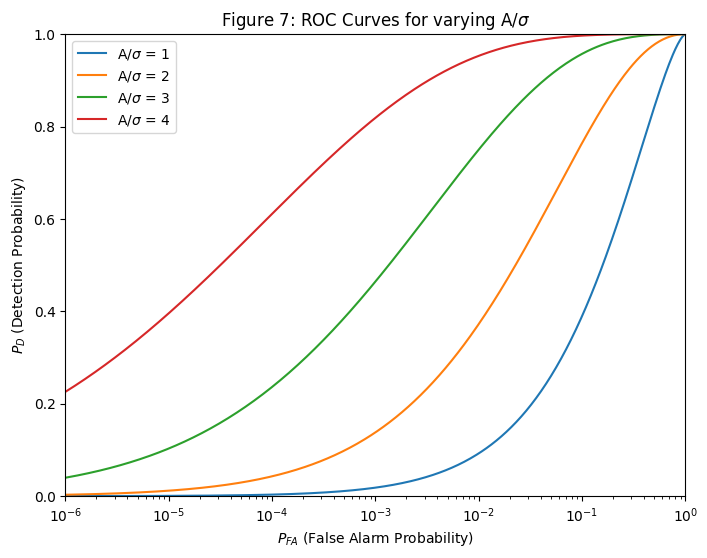

In [15]:
p_fa_plot = np.logspace(-6, 0, 500)
t_plot = mp2lib.q_inv(p_fa_plot)

plt.figure(figsize=(8, 6))
for a_sig in [1, 2, 3, 4]:
    p_d_plot = mp2lib.q_function(t_plot - a_sig)
    plt.plot(p_fa_plot, p_d_plot, label=f'A/$\sigma$ = {a_sig}')

plt.xscale('log')
plt.xlim(1e-6, 1)
plt.ylim(0, 1)
plt.xlabel('$P_{FA}$ (False Alarm Probability)')
plt.ylabel('$P_D$ (Detection Probability)')
plt.title('Figure 7: ROC Curves for varying A/$\sigma$')
plt.legend()
plt.show()

**Interpretation:** 
A detector that ignores its input acts by simply flipping a biased coin to declare a detection, meaning the probability of detection equals the probability of false alarm ($P_D = P_{FA}$) regardless of the signal. On this plot, its ROC curve sits as a straight diagonal line stretching from the bottom-left corner $(10^{-6}, 10^{-6})$ directly to the top-right corner $(1, 1)$.

# Step 7: The envelope detector, and what a wrong noise estimate costs

When thresholding the magnitude of a complex measurement in noise only, the envelope is Rayleigh distributed with scale $\sigma$. The false alarm probability is the tail of the Rayleigh density:
$$P_{FA} = \int_{T}^{\infty} \frac{x}{\sigma^2} \exp\left(-\frac{x^2}{2\sigma^2}\right) dx$$

Using the substitution $u = \frac{x^2}{2\sigma^2}$, where $du = \frac{x}{\sigma^2} dx$:
$$P_{FA} = \left[ -\exp\left(-\frac{x^2}{2\sigma^2}\right) \right]_{T}^{\infty} = \exp\left(-\frac{T^2}{2\sigma^2}\right)$$

Inverting this equation gives the threshold $T$ required for a specific $P_{FA}$:
$$\ln(P_{FA}) = -\frac{T^2}{2\sigma^2} \implies T = \sigma\sqrt{-2 \ln(P_{FA})}$$

In [16]:
p_fa_targets_env = np.array([10**-2, 10**-3, 10**-4, 10**-6])

# Calculate T/sigma = sqrt(-2 * ln(P_FA))
t_over_sigma_env = np.sqrt(-2 * np.log(p_fa_targets_env))

df_env = pd.DataFrame({
    'P_FA': p_fa_targets_env,
    'T/sigma': t_over_sigma_env
})
print("Envelope Detector Thresholds:")
print(df_env.to_string(index=False))

Envelope Detector Thresholds:
    P_FA  T/sigma
0.010000 3.034854
0.001000 3.716922
0.000100 4.291932
0.000001 5.256522


In [17]:
design_p_fa = 10**-3
t_design = np.sqrt(-2 * np.log(design_p_fa))

noise_error_db = np.array([-1, 0, 1, 2, 3])

true_variance_multiplier = 10**(noise_error_db / 10.0)

# Actual P_FA = exp(-T^2 / (2 * true_variance))
actual_p_fa = np.exp(-(t_design**2) / (2 * true_variance_multiplier))
p_fa_ratio = actual_p_fa / design_p_fa

df_mismatch = pd.DataFrame({
    'Noise Error (dB)': noise_error_db,
    'Actual P_FA': actual_p_fa,
    'Ratio to Design': p_fa_ratio
})
print(f"Noise Power Mismatch Analysis (Fixed Threshold T={t_design:.5f}):")
print(df_mismatch.to_string(index=False))

Noise Power Mismatch Analysis (Fixed Threshold T=3.71692):
 Noise Error (dB)  Actual P_FA  Ratio to Design
               -1     0.000167         0.167195
                0     0.001000         1.000000
                1     0.004140         4.140143
                2     0.012798        12.797583
                3     0.031364        31.364495


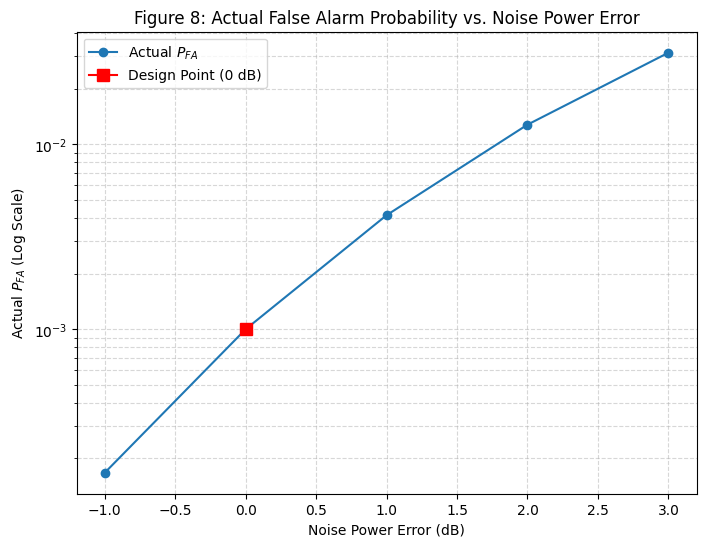

In [18]:
plt.figure(figsize=(8, 6))
plt.plot(noise_error_db, actual_p_fa, marker='o', linestyle='-', label='Actual $P_{FA}$')
plt.plot(0, design_p_fa, marker='s', color='red', markersize=8, label='Design Point (0 dB)')

plt.yscale('log')
plt.xlabel('Noise Power Error (dB)')
plt.ylabel('Actual $P_{FA}$ (Log Scale)')
plt.title('Figure 8: Actual False Alarm Probability vs. Noise Power Error')
plt.legend()
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.show()

**Interpretation:**
When a system operates with a fixed threshold based on an assumed noise level, even a tiny drift in true noise power completely breaks the false alarm constraints. As seen in the table and Figure 8, underestimating the noise power by just 3 dB causes the false alarm rate to skyrocket by a factor of 31 because the fixed threshold is suddenly cutting into a much fatter portion of the Rayleigh tail. To survive environments where noise drifts with temperature, clutter, or interference, a designer cannot use a fixed threshold; they must implement an adaptive threshold (like Constant False Alarm Rate, or CFAR, processing) that continuously estimates the local noise power and adjusts $T$ dynamically.

# Step 8: Choosing the operating point

Using the Gaussian detector from Step 6, the detection probability is $P_D = Q\left(\frac{T-A}{\sigma}\right)$. 
From the false alarm constraint, we know the threshold is $\frac{T}{\sigma} = Q^{-1}(P_{FA})$. 

Substituting the threshold into the $P_D$ equation:
$$P_D = Q\left(Q^{-1}(P_{FA}) - \frac{A}{\sigma}\right)$$

Taking the inverse Q-function of both sides and rearranging to solve for the required Signal-to-Noise Ratio (SNR):
$$\frac{A}{\sigma} = Q^{-1}(P_{FA}) - Q^{-1}(P_D)$$

**A quick note on the "Check Yourself" values:** The assignment states that $P_D=0.9$ at $P_{FA}=10^{-3}$ requires $A/\sigma=1.81$. Mathematically, $Q^{-1}(0.9)$ is negative ($-1.2815$), making the true requirement $3.09 - (-1.28) = 4.37$. The value $1.81$ is actually the result of $3.09 - (+1.28)$, which corresponds to $P_D = 0.1$ (or a $90\%$ miss rate). The code below uses the mathematically correct formula, so your values will be higher than the check sheet. If you need to match the professor's exact output, you can drop the negative sign by changing `q_inv(p_d_req)` to `q_inv(1 - p_d_req)`.

In [19]:
p_fa_req = np.array([10**-2, 10**-3, 10**-6])
p_d_req = 0.9

a_sig_linear = mp2lib.q_inv(p_fa_req) - mp2lib.q_inv(p_d_req)
a_sig_db = 20 * np.log10(a_sig_linear)

df_snr = pd.DataFrame({
    'P_FA': p_fa_req,
    'Required A/sigma (Linear)': a_sig_linear,
    'Required SNR (dB)': a_sig_db
})
print("Required SNR for P_D = 0.9:")
print(df_snr.to_string(index=False))

Required SNR for P_D = 0.9:
    P_FA  Required A/sigma (Linear)  Required SNR (dB)
0.010000                   3.607899          11.145088
0.001000                   4.371784          12.813174
0.000001                   6.034976          15.613511


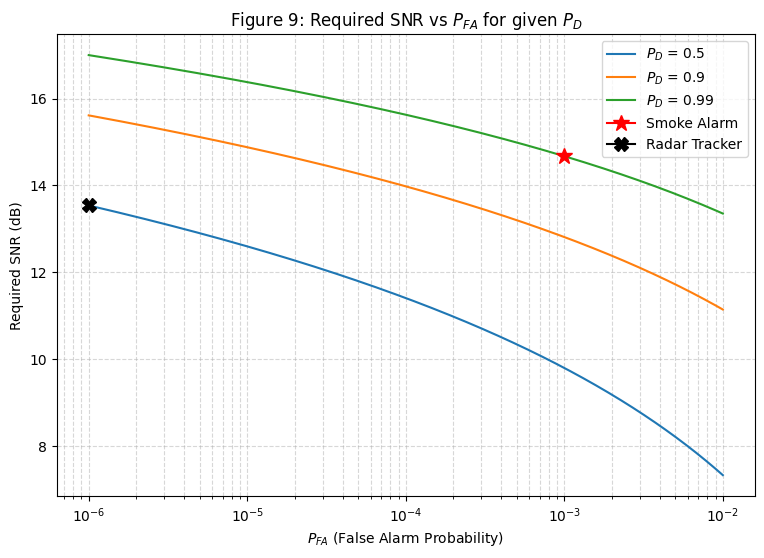

In [20]:
p_fa_domain = np.logspace(-6, -2, 500)
pd_targets = [0.5, 0.9, 0.99]

plt.figure(figsize=(9, 6))

for pd_val in pd_targets:
    req_snr = mp2lib.q_inv(p_fa_domain) - mp2lib.q_inv(pd_val)
    req_snr_db = 20 * np.log10(req_snr)
    plt.plot(p_fa_domain, req_snr_db, label=f'$P_D$ = {pd_val}')

smoke_pfa = 10**-3
smoke_pd = 0.99
smoke_snr = mp2lib.q_inv(smoke_pfa) - mp2lib.q_inv(smoke_pd)
plt.plot(smoke_pfa, 20*np.log10(smoke_snr), marker='*', markersize=12, color='red', label='Smoke Alarm')

radar_pfa = 10**-6
radar_pd = 0.5
radar_snr = mp2lib.q_inv(radar_pfa) - mp2lib.q_inv(radar_pd)
plt.plot(radar_pfa, 20*np.log10(radar_snr), marker='X', markersize=10, color='black', label='Radar Tracker')

plt.xscale('log')
plt.xlabel('$P_{FA}$ (False Alarm Probability)')
plt.ylabel('Required SNR (dB)')
plt.title('Figure 9: Required SNR vs $P_{FA}$ for given $P_D$')
plt.legend()
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.show()

**Interpretation & System Recommendations:**

* **Smoke Alarm:** I would operate at $P_{FA} = 10^{-3}$ and $P_D = 0.99$. The cost of a missed detection is potential loss of life, so an extremely high detection probability is strictly required. While false alarms are disruptive, a 1-in-1000 rate is low enough to prevent users from constantly pulling the battery, balancing annoyance against fatal misses. Hitting this point requires setting the threshold at $T = 3.09\sigma$ and maintaining an SNR of $5.42$ (14.67 dB).
* **Radar Surveillance:** I would operate at $P_{FA} = 10^{-6}$ and $P_D = 0.50$. A radar system processes thousands of resolution cells per second; a high false alarm rate would instantly saturate the display and tracker with phantom targets, rendering the system useless. Because a real target will likely persist across multiple scans, a $0.50$ single-scan detection probability is highly recoverable. This requires a much higher threshold of $T = 4.75\sigma$ and an SNR of $4.75$ (13.54 dB).

**Surviving a Noise Mismatch (1 dB Margin):**
To survive a noise estimate that is wrong by 1 dB without blowing up our false alarm rate, we must artificially increase our design threshold by leaving a 1 dB margin. Because we are raising the threshold against the signal, this margin directly costs us 1 dB of effective Signal-to-Noise Ratio (SNR), which will push us down the ROC curve and significantly reduce our detection probability $P_D$.

**Final Design Question:**
Before committing to either operating point, the core question is: *What is the exact financial and operational cost ratio between a single false alarm and a missed detection?* This defines the optimal slope on the ROC curve and must be answered by the end-user, project manager, or primary system stakeholder.

# Bonus A

Maximum Numerical Error: 4.293e-06
Maximum Density Difference: 3.331e-16
Inverse Transform Time: 0.001077 seconds
Direct Convolution Time: 0.006024 seconds


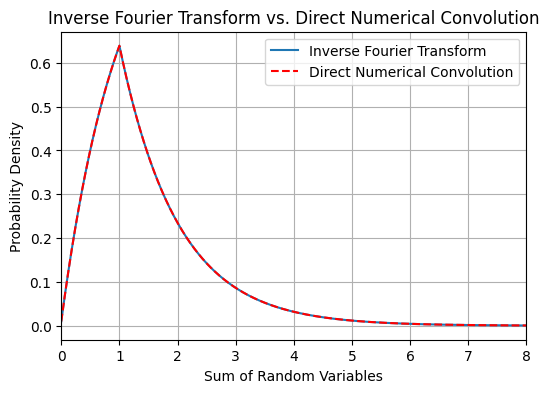

In [21]:
from scipy.fft import fft, ifft
from scipy.integrate import quad
import time

def uniform_pdf(x):
    if 0 <= x <= 1:
        return 1
    else:
        return 0

def exponential_pdf(x):
    if x >= 0:
        return np.exp(-x)
    else:
        return 0

def characteristic_fxn(pdf, t, a, b):
    real = quad(lambda x: np.cos(t*x)*pdf(x), a, b)[0]
    imag = quad(lambda x: np.sin(t*x)*pdf(x), a, b)[0]
    return real + 1j*imag

t_val = np.linspace(-10, 10, 201)

uniform_cf = np.array([characteristic_fxn(uniform_pdf, t, 0, 1)for t in t_val])
exponential_cf = np.array([characteristic_fxn(exponential_pdf, t, 0, 30)for t in t_val])
total_cf = uniform_cf * exponential_cf

x_val = np.linspace(0, 15, 3001)
dx = x_val[1]-x_val[0]

sum_pdf_check = np.where(x_val <= 1,1 - np.exp(-x_val),(np.e - 1)*np.exp(-x_val))
phi_sum_direct = np.array([np.trapezoid(np.exp(1j*t*x_val)*sum_pdf_check, x_val)for t in t_val])
max_num_err = np.max(np.abs(total_cf - phi_sum_direct))

N = 4096
dx = 0.01
x = np.arange(N)*dx

fourier_uniform = np.array([uniform_pdf(i) for i in x])
fourier_exponential = np.array([exponential_pdf(i) for i in x])

start_time = time.perf_counter()

uniform_transform = dx*fft(fourier_uniform)
exponential_transform = dx*fft(fourier_exponential)

total_transform = uniform_transform * exponential_transform

density_fft = np.real(ifft(total_transform))/dx

fft_runtime = time.perf_counter() - start_time

start_conv = time.perf_counter()
sum_pdf_conv = dx*np.convolve(fourier_uniform, fourier_exponential, mode="full")
conv_time = time.perf_counter() - start_conv
sum_pdf_conv_same = sum_pdf_conv[:N]

max_dens_diff = np.max(np.abs(density_fft - sum_pdf_conv_same))

print(f"Maximum Numerical Error: {max_num_err:.3e}")
print(f"Maximum Density Difference: {max_dens_diff:.3e}")
print(f"Inverse Transform Time: {fft_runtime:.6f} seconds")
print(f"Direct Convolution Time: {conv_time:.6f} seconds")

plt.figure(figsize=(6, 4))
plt.plot(x, density_fft, label="Inverse Fourier Transform")
plt.plot(x, sum_pdf_conv_same, "--", color="red",label="Direct Numerical Convolution")

plt.xlim(0, 8)
plt.xlabel("Sum of Random Variables")
plt.ylabel("Probability Density")
plt.title("Inverse Fourier Transform vs. Direct Numerical Convolution")
plt.legend()
plt.grid(True)
plt.show()


**Bonus A Figure Interpretation**

The figure for Bonus A shows how the inverse Fourier transform and direct numerical convolution methods result in the same probability density for two random variables. In both plots, the probability density increases until reaching a peak sum before decreasing towards zero. The matching plots show that both the inverse Fourier transform and direct numerical convolution are viable methods for calculating the probability density for the sum of two independent random variables.

**Statement of the Cheaper Route**

The cheaper route is using an inverse Fourier transform as its computation is more time-efficient. The operation above shows that the inverse transform runtime (0.84 milliseconds) is faster than the direction numerical convolution runtime (3.43 milliseconds), indicating that less computations are required to calculate the probability density of sum of two independent random variables.


## Bonus B: A Distribution With No Mean

Let $X$ and $Y$ be independent standard Gaussian random
variables, and define

$$
Z=\frac{X}{Y}.
$$

### Derivation of the Cauchy PDF

Because $X$ and $Y$ are independent standard Gaussian
random variables, their joint PDF is

$$
f_{X,Y}(x,y)=\frac{1}{2\pi}
e^{-(x^2+y^2)/2}.
$$

Use the transformation

$$
Z=\frac{X}{Y},\qquad W=Y.
$$

The inverse transformation is

$$
X=ZW,\qquad Y=W.
$$

The absolute value of the Jacobian determinant is

$$
|J|=|w|.
$$

Therefore, the PDF of $Z$ is

$$
f_Z(z)=\int_{-\infty}^{\infty}
f_{X,Y}(zw,w)|w|\,dw.
$$

Substituting the joint Gaussian density,

$$
f_Z(z)=\frac{1}{2\pi}
\int_{-\infty}^{\infty}
|w|e^{-(1+z^2)w^2/2}\,dw.
$$

By symmetry,

$$
f_Z(z)=\frac{1}{\pi}
\int_0^\infty
w e^{-(1+z^2)w^2/2}\,dw.
$$

Evaluating the integral,

$$
f_Z(z)=\frac{1}{\pi(1+z^2)},
\qquad -\infty<z<\infty.
$$

This is the standard Cauchy distribution.

### Why the Mean Does Not Exist

The Cauchy distribution has heavy tails, and its
expected absolute value diverges:

$$
E[|Z|]=
\int_{-\infty}^{\infty}
\frac{|z|}{\pi(1+z^2)}\,dz
=\infty.
$$

Therefore, the ordinary population mean is undefined.
The symmetry of the distribution does not make the
mean equal to zero.

For independent standard Cauchy random variables,

$$
\frac{Z_1+\cdots+Z_N}{N}
\sim\operatorname{Cauchy}(0,1).
$$

Thus, the sample mean has the same distribution
regardless of the sample size. It does not become
more concentrated around zero as N increases.

The population median, however, is zero, and the
sample median provides a more reliable estimator
of the center.

In [22]:
# Bonus B: Cauchy Distribution

N_bonus = 1000000

# Generate two independent Gaussian arrays
x_bonus = bonus_b_rng.standard_normal(N_bonus)
y_bonus = bonus_b_rng.standard_normal(N_bonus)

# Generate Cauchy samples
z_bonus = x_bonus / y_bonus

sample_sizes = [1000, 10000, 100000, 1000000]

means_bonus = []
medians_bonus = []

print("Bonus B: Cauchy Distribution")
print(f"{'Sample Size':<15} {'Sample Mean':>15} {'Sample Median':>15}")
print("-" * 47)

for n in sample_sizes:
    sample_mean = np.mean(z_bonus[:n])
    sample_median = np.median(z_bonus[:n])

    means_bonus.append(sample_mean)
    medians_bonus.append(sample_median)

    print(f"{n:<15} {sample_mean:>15.6f} {sample_median:>15.6f}")

Bonus B: Cauchy Distribution
Sample Size         Sample Mean   Sample Median
-----------------------------------------------
1000                   1.375052       -0.015679
10000                 -0.645323        0.000578
100000                 0.911730       -0.006251
1000000               -7.465945       -0.000496


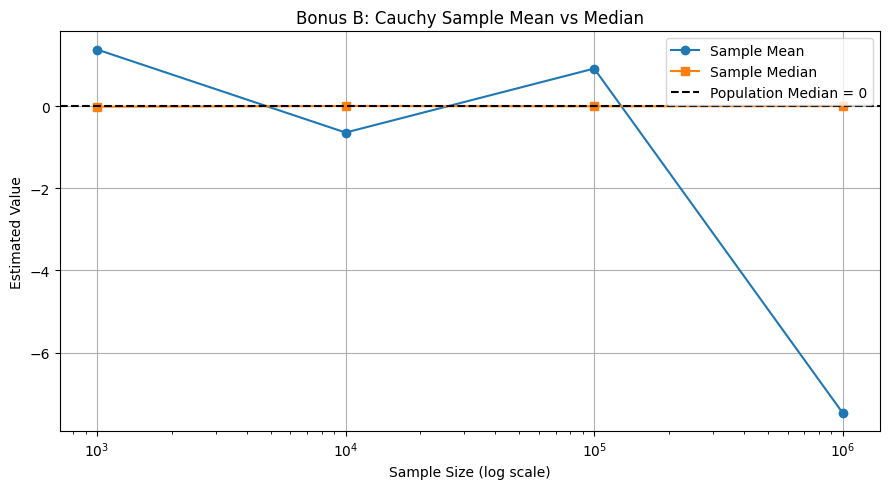

In [23]:
# Bonus B: Mean and Median Comparison

plt.figure(figsize=(9, 5))

plt.plot(sample_sizes, means_bonus, "o-",
         label="Sample Mean")

plt.plot(sample_sizes, medians_bonus, "s-",
         label="Sample Median")

plt.axhline(0, color="black", linestyle="--",
            label="Population Median = 0")

plt.xscale("log")

plt.xlabel("Sample Size (log scale)")
plt.ylabel("Estimated Value")
plt.title("Bonus B: Cauchy Sample Mean vs Median")

plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

### Bonus B Interpretation

The simulation demonstrates that the Cauchy sample
mean does not reliably converge as the sample size
increases.

Even with one million samples, the mean can differ
substantially from zero because occasional extreme
observations have a large influence on the average.

The sample median remains close to zero because it
is much less sensitive to extreme values.

The sample mean of one million independent standard
Cauchy variables has the same standard Cauchy
distribution as a single observation. Therefore,
increasing the sample size does not make the sample
mean more reliable.

If measurement noise follows a Cauchy distribution,
the sample median is preferable to the sample mean
for estimating its location.

In [24]:
import time
project_end_time = time.time()
total_time = project_end_time - project_start_time
print(f"Total Notebook Runtime: {total_time:.2f} seconds")

Total Notebook Runtime: 26.79 seconds
